# London undirected interaction network

This notebook summarizes and plots the statistics related to the London undirected reply–mention interaction network.

The statistics were extracted via this code: 03_network_descriptives_undirected.py

The notebook reports network-level statistics, the undirected edge-weight distribution, node degree and strength, connected components, and a compact visualization of the high-degree network core.


### Settings


In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import plotly.graph_objects as go
from matplotlib.ticker import PercentFormatter, FuncFormatter, MaxNLocator
from sqlalchemy import create_engine, text, bindparam
from sqlalchemy.engine import URL
from IPython.display import display, HTML

%matplotlib inline

BASE_DIR = "/mnt/common-hdd/group-dirs/twitter-2025-project/interaction_network_descriptives/undirected"
SUMMARY_CSV = os.path.join(BASE_DIR, "interaction_network_undirected_london_summary.csv")
NODES_CSV = os.path.join(BASE_DIR, "interaction_network_undirected_london_nodes.csv")
EDGE_WEIGHT_DISTRIBUTION_CSV = os.path.join(BASE_DIR, "interaction_network_undirected_london_edge_weight_distribution.csv")
COMPONENT_DISTRIBUTION_CSV = os.path.join(BASE_DIR, "interaction_network_undirected_london_component_distribution.csv")
PLOT_DIR = os.path.join(BASE_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

CONNECTION_PATH = "/home/ilyesvirag/twitter/venv/connection.json"
NETWORK_TABLE = "interaction_network_undirected"
CITY = "london"


### Read descriptive outputs


In [2]:
summary = pd.read_csv(SUMMARY_CSV)
nodes = pd.read_csv(NODES_CSV)
edge_weight_distribution = pd.read_csv(EDGE_WEIGHT_DISTRIBUTION_CSV)
component_distribution = pd.read_csv(COMPONENT_DISTRIBUTION_CSV)

print(f"Nodes loaded: {len(nodes):,}")
print(f"Edge-weight distribution rows: {len(edge_weight_distribution):,}")
print(f"Component-distribution rows: {len(component_distribution):,}")


Nodes loaded: 10,350,047
Edge-weight distribution rows: 2,085
Component-distribution rows: 100,943


### Helper functions


In [3]:
def cumulative_distribution(series):
    values = pd.to_numeric(series, errors="coerce").dropna().to_numpy()
    values = values[values > 0]
    if len(values) == 0:
        return pd.DataFrame(columns=["x", "n_geq", "share_geq"])

    unique_values, counts = np.unique(values, return_counts=True)
    n_geq = counts[::-1].cumsum()[::-1]
    return pd.DataFrame({"x": unique_values, "n_geq": n_geq, "share_geq": n_geq / counts.sum()})


def default_xmax(series, quantile=0.99, minimum=10):
    values = pd.to_numeric(series, errors="coerce").dropna()
    values = values[values > 0]
    return minimum if len(values) == 0 else max(minimum, int(np.ceil(values.quantile(quantile))))


def threshold_summary(series, thresholds, value_name="minimum_value"):
    values = pd.to_numeric(series, errors="coerce").dropna()
    n_total = len(values)
    rows = []
    for threshold in thresholds:
        n_geq = int((values >= threshold).sum())
        rows.append({value_name: threshold, "n_users": n_geq,
                     "share_users": 100 * n_geq / n_total if n_total > 0 else np.nan})
    return pd.DataFrame(rows)


def plot_cumulative_share(series, xlabel, title, filename, xmax=None):
    dist = cumulative_distribution(series)
    if dist.empty:
        return

    xmax = default_xmax(series) if xmax is None else xmax
    plot_data = dist.loc[dist["x"] <= xmax].copy()

    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.plot(plot_data["x"], plot_data["share_geq"], linewidth=1.8)
    ax.set_xlim(1, xmax)
    ax.set_ylim(0, 1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Share with value at least x")
    ax.set_title(title)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(os.path.join(PLOT_DIR, filename), dpi=300, bbox_inches="tight")
    plt.show()


def plot_cumulative_count(series, xlabel, title, filename, xmax=None):
    dist = cumulative_distribution(series)
    if dist.empty:
        return

    xmax = default_xmax(series) if xmax is None else xmax
    plot_data = dist.loc[dist["x"] <= xmax].copy()

    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.plot(plot_data["x"], plot_data["n_geq"], linewidth=1.8)
    ax.set_xlim(1, xmax)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number with value at least x")
    ax.set_title(title)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value / 1_000_000:.1f}M" if value >= 1_000_000 else f"{value:,.0f}"))
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(os.path.join(PLOT_DIR, filename), dpi=300, bbox_inches="tight")
    plt.show()


def plot_measure_pair(series, xlabel, title_base, filename_base, xmax=None):
    plot_cumulative_share(series, xlabel, f"{title_base}: share", f"{filename_base}_share.png", xmax=xmax)
    plot_cumulative_count(series, xlabel, f"{title_base}: raw count", f"{filename_base}_count.png", xmax=xmax)


def component_size_categories(series):
    values = pd.to_numeric(series, errors="coerce")
    bins = [0, 1, 2, 5, 10, 50, 100, 1000, np.inf]
    labels = ["1", "2", "3–5", "6–10", "11–50", "51–100", "101–1,000", "1,001+"]
    return pd.cut(values, bins=bins, labels=labels, include_lowest=True)


def component_category_summary(component_df):
    subset = component_df.copy()
    subset["size_category"] = component_size_categories(subset["n_nodes"])
    dist = subset["size_category"].value_counts(sort=False).rename_axis("component_size").reset_index(name="n_components")
    dist["share_components"] = 100 * dist["n_components"] / dist["n_components"].sum()
    return dist


def plot_component_categories(dist, y_type, filename):
    fig, ax = plt.subplots(figsize=(8, 5))

    if y_type == "share":
        y = dist["share_components"] / 100
        ylabel = "Share of components"
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    else:
        y = dist["n_components"]
        ylabel = "Number of components"
        ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))

    ax.bar(dist["component_size"].astype(str), y)
    ax.set_xlabel("Component size (number of users)")
    ax.set_ylabel(ylabel)
    ax.set_title("London undirected interaction network: component sizes")
    ax.grid(True, axis="y", alpha=0.25)
    plt.xticks(rotation=30, ha="right")
    fig.tight_layout()
    fig.savefig(os.path.join(PLOT_DIR, filename), dpi=300, bbox_inches="tight")
    plt.show()


In [4]:
def descriptive_summary(series, measure_name):
    values = pd.Series(pd.to_numeric(series, errors="coerce")).dropna()

    if len(values) == 0:
        stats = {"n": 0, "sum": np.nan, "mode": np.nan, "mean": np.nan, "median": np.nan,
                 "p75": np.nan, "p90": np.nan, "p95": np.nan, "p99": np.nan, "max": np.nan}
    else:
        modes = values.mode(dropna=True)
        stats = {
            "n": len(values), "sum": values.sum(),
            "mode": modes.iloc[0] if len(modes) else np.nan,
            "mean": values.mean(), "median": values.median(),
            "p75": values.quantile(0.75), "p90": values.quantile(0.90),
            "p95": values.quantile(0.95), "p99": values.quantile(0.99), "max": values.max()
        }

    return pd.DataFrame({"measure": measure_name, "statistic": list(stats.keys()), "value": list(stats.values())})


def weighted_descriptive_summary(values, counts, measure_name):
    df = pd.DataFrame({"value": pd.to_numeric(values, errors="coerce"),
                       "count": pd.to_numeric(counts, errors="coerce")}).dropna()
    df = df.loc[df["count"] > 0].sort_values("value").copy()

    if len(df) == 0:
        stats = {"n": 0, "sum": np.nan, "mode": np.nan, "mean": np.nan, "median": np.nan,
                 "p75": np.nan, "p90": np.nan, "p95": np.nan, "p99": np.nan, "max": np.nan}
    else:
        total = df["count"].sum()
        df["cum_count"] = df["count"].cumsum()

        def weighted_quantile(q):
            return df.loc[df["cum_count"] >= q * total, "value"].iloc[0]

        stats = {
            "n": int(total), "sum": (df["value"] * df["count"]).sum(),
            "mode": df.loc[df["count"].idxmax(), "value"],
            "mean": np.average(df["value"], weights=df["count"]),
            "median": weighted_quantile(0.50), "p75": weighted_quantile(0.75),
            "p90": weighted_quantile(0.90), "p95": weighted_quantile(0.95),
            "p99": weighted_quantile(0.99), "max": df["value"].max()
        }

    return pd.DataFrame({"measure": measure_name, "statistic": list(stats.keys()), "value": list(stats.values())})


## 1. Overall network summary


In [5]:
summary_display = summary.copy()
summary_display

,metric,description,value
0,nodes,Number of unique users appearing in the London...,10350047
1,undirected_edges,Number of distinct non-self undirected user-us...,40007328
2,total_interactions,Total number of tweet-level interactions repre...,117232348
3,network_density,Observed undirected edges divided by the numbe...,7.469386639835151e-07
4,reply_only_interactions,Total number of reply-only tweet-level interac...,13768305
5,mention_only_interactions,Total number of mention-only tweet-level inter...,62494053
6,both_interactions,Total number of interactions classified as bot...,40969990
7,share_reply_only,Share of all tweet-level interactions classifi...,0.11744458961105173
8,share_mention_only,Share of all tweet-level interactions classifi...,0.5330785748657018
9,share_both,Share of all tweet-level interactions classifi...,0.34947683552324654


## 2. Edge-level structure: undirected edge weight


**Edge weight**: total number of tweet-level interactions observed between a pair of users, regardless of direction. 
If `A → B` occurs 7 times and `B → A` occurs 4 times, the undirected `A — B` edge has weight 11.


In [6]:
edge_weight_descriptives = weighted_descriptive_summary(
    edge_weight_distribution["edge_weight"],
    edge_weight_distribution["n_edges"],
    "Undirected edge weight"
)
edge_weight_descriptives


,measure,statistic,value
0,Undirected edge weight,n,4.000733e+07
1,Undirected edge weight,sum,1.172323e+08
2,Undirected edge weight,mode,1.000000e+00
3,Undirected edge weight,mean,2.930272e+00
4,Undirected edge weight,median,1.000000e+00
5,Undirected edge weight,p75,2.000000e+00
6,Undirected edge weight,p90,4.000000e+00
7,Undirected edge weight,p95,8.000000e+00
8,Undirected edge weight,p99,2.900000e+01
9,Undirected edge weight,max,1.776100e+04


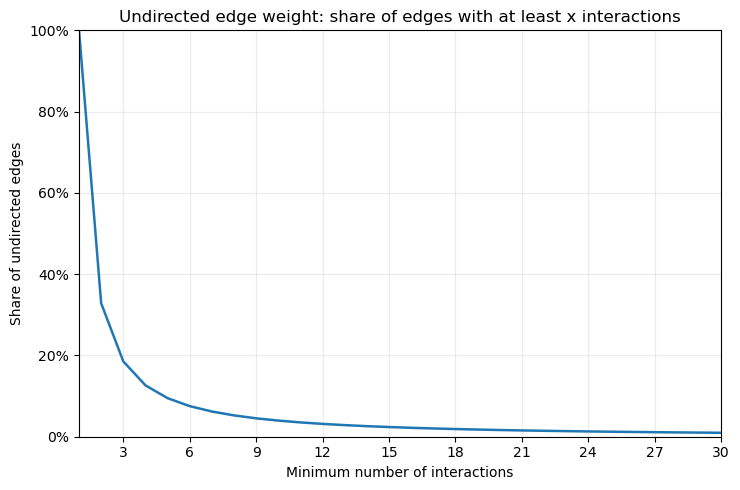

In [7]:
edge_dist = edge_weight_distribution.loc[
    (edge_weight_distribution["edge_weight"] > 0) & (edge_weight_distribution["n_edges"] > 0)
].sort_values("edge_weight").copy()

edge_dist["n_edges_geq"] = edge_dist["n_edges"].iloc[::-1].cumsum().iloc[::-1]
edge_dist["share_edges_geq"] = edge_dist["n_edges_geq"] / edge_dist["n_edges"].sum()

EDGE_XMAX = 30
plot_data = edge_dist.loc[edge_dist["edge_weight"] <= EDGE_XMAX].copy()

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(plot_data["edge_weight"], plot_data["share_edges_geq"], linewidth=1.8)
ax.set_xlim(1, EDGE_XMAX)
ax.set_ylim(0, 1)
ax.set_xlabel("Minimum number of interactions")
ax.set_ylabel("Share of undirected edges")
ax.set_title("Undirected edge weight: share of edges with at least x interactions")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "edge_weight_cumulative_share.png"), dpi=300, bbox_inches="tight")
plt.show()


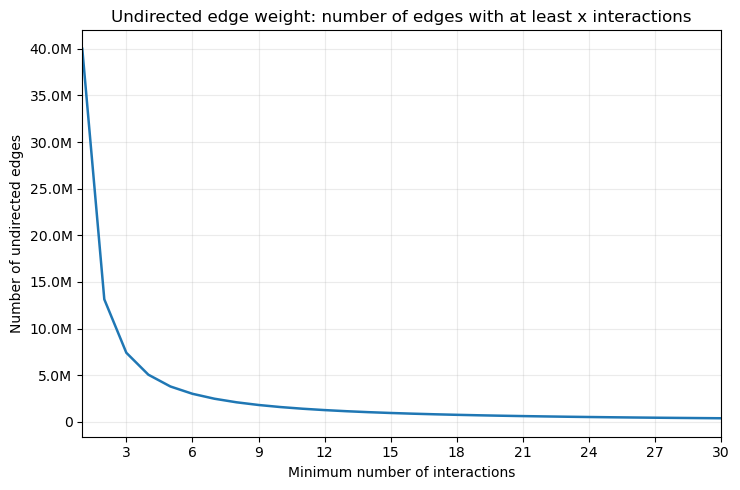

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(plot_data["edge_weight"], plot_data["n_edges_geq"], linewidth=1.8)
ax.set_xlim(1, EDGE_XMAX)
ax.set_xlabel("Minimum number of interactions")
ax.set_ylabel("Number of undirected edges")
ax.set_title("Undirected edge weight: number of edges with at least x interactions")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value / 1_000_000:.1f}M" if value >= 1_000_000 else f"{value:,.0f}"))
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "edge_weight_cumulative_count.png"), dpi=300, bbox_inches="tight")
plt.show()


In [9]:
edge_thresholds = [1, 2, 3, 5, 10, 20, 30, 50, 100]
edge_threshold_summary = []

for threshold in edge_thresholds:
    n_edges = int(edge_dist.loc[edge_dist["edge_weight"] >= threshold, "n_edges"].sum())
    edge_threshold_summary.append({
        "minimum_interactions": threshold,
        "n_undirected_edges": n_edges,
        "share_undirected_edges": 100 * n_edges / edge_dist["n_edges"].sum()
    })

edge_threshold_summary = pd.DataFrame(edge_threshold_summary)
edge_threshold_summary


,minimum_interactions,n_undirected_edges,share_undirected_edges
0,1,40007328,100.000000
1,2,13139608,32.843003
2,3,7411988,18.526576
3,5,3795708,9.487532
4,10,1588064,3.969433
5,20,660042,1.649803
6,30,388278,0.970517
7,50,194649,0.486533
8,100,72536,0.181307


## 3. Node-level connectivity: degree


**Degree**: number of distinct users with whom a user has at least one interaction (unique neighbors), regardless of direction.


In [10]:
degree_descriptives = descriptive_summary(nodes["degree"], "Degree")
degree_descriptives


,measure,statistic,value
0,Degree,n,1.035005e+07
1,Degree,sum,8.001466e+07
2,Degree,mode,1.000000e+00
3,Degree,mean,7.730850e+00
4,Degree,median,1.000000e+00
5,Degree,p75,3.000000e+00
6,Degree,p90,8.000000e+00
7,Degree,p95,2.000000e+01
8,Degree,p99,1.100000e+02
9,Degree,max,4.199500e+04


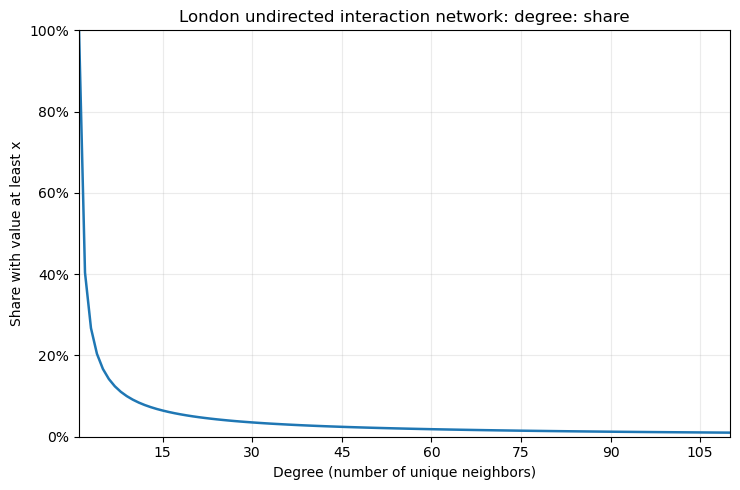

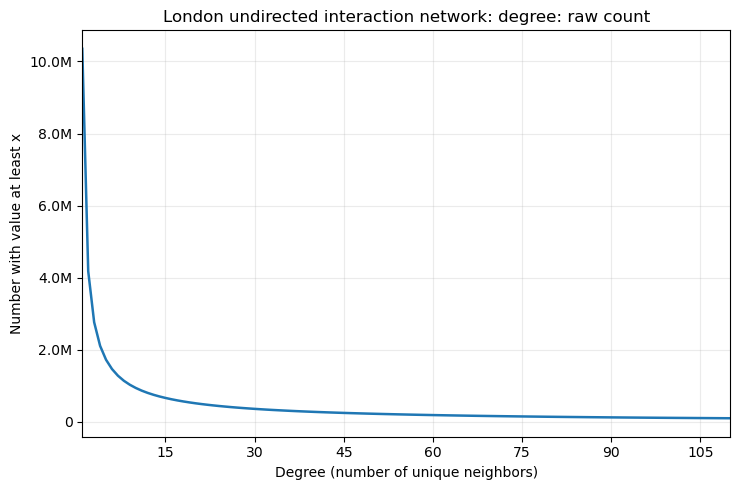

In [11]:
plot_measure_pair(
    nodes["degree"],
    "Degree (number of unique neighbors)",
    "London undirected interaction network: degree",
    "degree"
)


In [12]:
degree_threshold_summary = threshold_summary(
    nodes["degree"], [1, 2, 3, 5, 10, 20, 50, 100, 500, 1000],
    value_name="minimum_degree"
)
degree_threshold_summary


,minimum_degree,n_users,share_users
0,1,10350047,100.000000
1,2,4179734,40.383720
2,3,2765683,26.721454
3,5,1725997,16.676224
4,10,944173,9.122403
5,20,520064,5.024750
6,50,228369,2.206454
7,100,114793,1.109106
8,500,16701,0.161362
9,1000,6124,0.059169


## 4. Node-level interaction intensity: strength


**Strength**: total number of interactions a user has across all of their connections.

In [13]:
strength_descriptives = descriptive_summary(nodes["strength"], "Strength")
strength_descriptives


,measure,statistic,value
0,Strength,n,1.035005e+07
1,Strength,sum,2.344647e+08
2,Strength,mode,1.000000e+00
3,Strength,mean,2.265349e+01
4,Strength,median,2.000000e+00
5,Strength,p75,6.000000e+00
6,Strength,p90,2.100000e+01
7,Strength,p95,5.100000e+01
8,Strength,p99,3.110000e+02
9,Strength,max,2.950620e+05


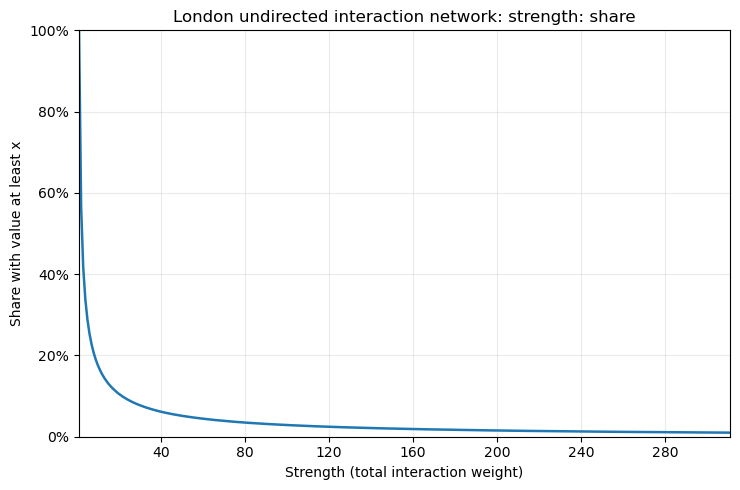

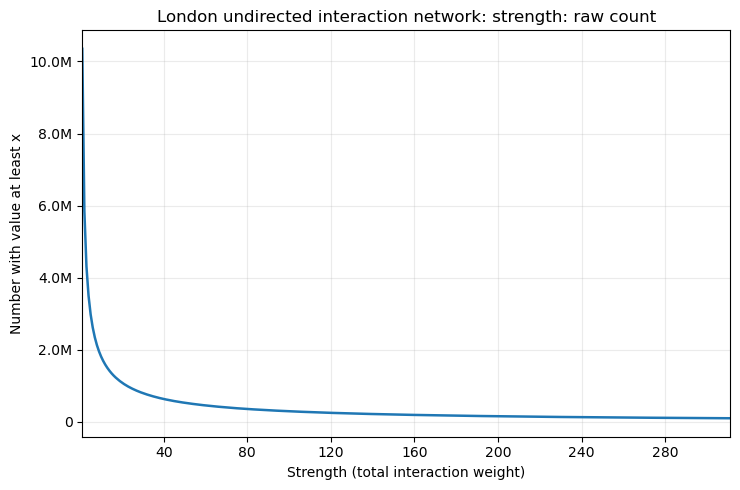

In [14]:
plot_measure_pair(
    nodes["strength"],
    "Strength (total interaction weight)",
    "London undirected interaction network: strength",
    "strength"
)


In [15]:
strength_threshold_summary = threshold_summary(
    nodes["strength"], [1, 2, 3, 5, 10, 20, 50, 100, 500, 1000],
    value_name="minimum_strength"
)
strength_threshold_summary


,minimum_strength,n_users,share_users
0,1,10350047,100.000000
1,2,5847470,56.497038
2,3,4311512,41.656932
3,5,2983953,28.830333
4,10,1816189,17.547640
5,20,1091014,10.541150
6,50,532856,5.148344
7,100,297694,2.876257
8,500,63234,0.610954
9,1000,29317,0.283255


## 5. Connected components


A **connected component** is a maximal set of users in which every user can be reached from every other user when edge direction is ignored.


In [16]:
component_size_summary = component_category_summary(component_distribution)
component_size_summary


,component_size,n_components,share_components
0,1,0,0.000000
1,2,65254,64.644403
2,3–5,29847,29.568172
3,6–10,4546,4.503532
4,11–50,1279,1.267052
5,51–100,15,0.014860
6,"101–1,000",1,0.000991
7,"1,001+",1,0.000991


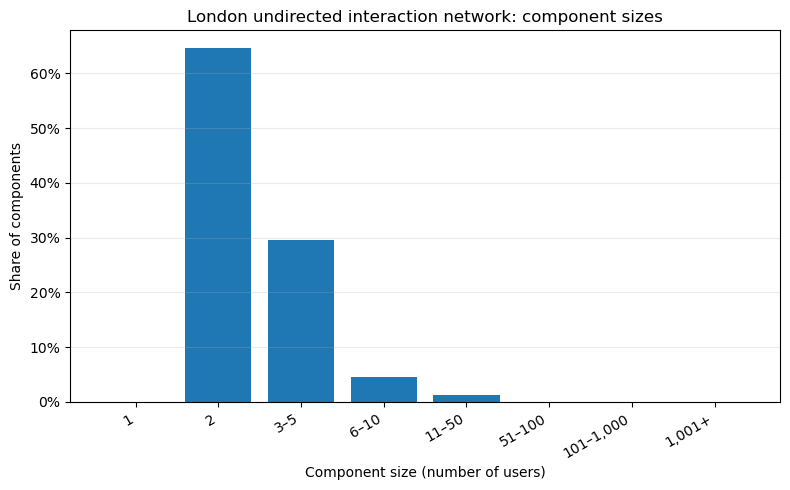

In [17]:
plot_component_categories(
    component_size_summary,
    "share",
    "component_size_categories_share.png"
)


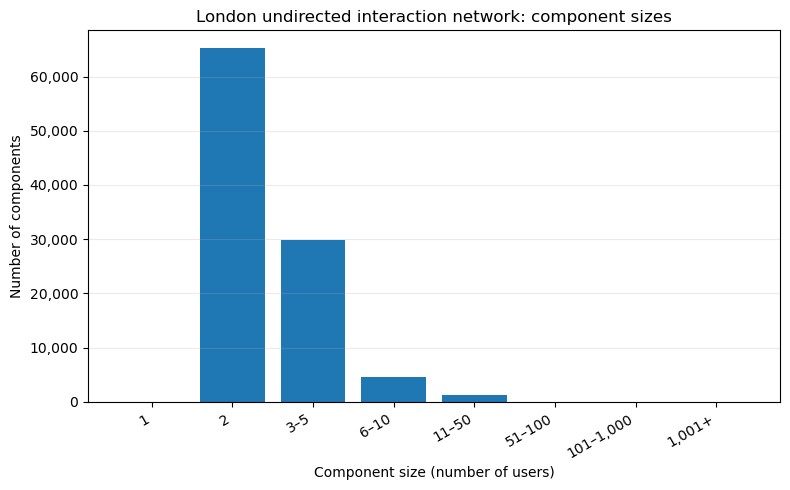

In [18]:
plot_component_categories(
    component_size_summary,
    "count",
    "component_size_categories_count.png"
)


### Giant component summary


In [19]:
giant_component_summary = summary.loc[
    summary["metric"].isin([
        "n_components",
        "giant_component_nodes",
        "share_nodes_in_giant_component",
        "giant_component_edges"
    ])
].copy()

giant_component_summary


,metric,description,value
34,n_components,Number of connected components in the undirect...,100943
35,giant_component_nodes,Number of users in the largest connected compo...,10061870
36,share_nodes_in_giant_component,Share of all users in the largest connected co...,0.9721569380312959
37,giant_component_edges,Number of undirected edges contained in the la...,39819690


## 7. Saved plots


In [20]:
print(f"Plots saved to: {PLOT_DIR}")
print("The interactive network visualization is saved as:")
print(os.path.join(PLOT_DIR, "undirected_high_degree_core_interactive.html"))


Plots saved to: /mnt/common-hdd/group-dirs/twitter-2025-project/interaction_network_descriptives/undirected/plots
The interactive network visualization is saved as:
/mnt/common-hdd/group-dirs/twitter-2025-project/interaction_network_descriptives/undirected/plots/undirected_high_degree_core_interactive.html
